# PHA films - water vapour permeability predictor

**Author:** Lab of Farm Structures
**Date:** 2026-11

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import shap
import seaborn as sns
from prince import FAMD
from xgboost import XGBRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, GroupKFold, KFold, RepeatedKFold, cross_val_predict, LeaveOneGroupOut
from scipy.stats import pearsonr
from scipy.spatial.distance import cdist
from scipy.stats import chi2_contingency, spearmanr
from sklearn.base import clone
import re
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as C, RBF, WhiteKernel, DotProduct

C:\Users\leoni\anaconda3\envs\polymer-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import warnings
warnings.filterwarnings("ignore")

## Load data

In [177]:
data_file = 'ANIPH_mclPHA_WVTR_database_v0.4.0_with_calc_1.xlsx'

df_all = pd.read_excel(data_file, sheet_name='WVTR_Data', header=1)
df_all.columns = df_all.columns.str.replace(' ', '_', regex=False)
df_all.head()

,Study_id,Instance,Sample_label,PHA_name,PHA_class,HB_ratio,HV_ratio,HHx_ratio,HO_ratio,HD_ratio,...,Property,Value,Unit,calc_unit_factor,calc_Value_std,calc_Value_std_unit,calc_WVP_SI,calc_log10_WVP,n,I_(%)
0,S001,1,With additives / without hot pressing,PHBHHx (Bluepha),scl-co-mcl,89.0,NaN,11.0,NaN,NaN,...,WVTR,3.981000e+02,g/(m2.day),1.0,3.981000e+02,g/(m2.day),NaN,NaN,3.0,62.0
1,S001,2,With additives / with hot pressing,PHBHHx (Bluepha),scl-co-mcl,89.0,NaN,11.0,NaN,NaN,...,WVTR,6.510000e+02,g/(m2.day),1.0,6.510000e+02,g/(m2.day),NaN,NaN,3.0,93.0
2,S001,3,Without additives / without hot pressing,PHBHHx (Bluepha),scl-co-mcl,89.0,NaN,11.0,NaN,NaN,...,WVTR,5.107000e+02,g/(m2.day),1.0,5.107000e+02,g/(m2.day),NaN,NaN,3.0,81.0
3,S001,4,Without additives / with hot pressing,PHBHHx (Bluepha),scl-co-mcl,89.0,NaN,11.0,NaN,NaN,...,WVTR,2.456000e+02,g/(m2.day),1.0,2.456000e+02,g/(m2.day),NaN,NaN,3.0,39.0
4,S002,1,151C / Annealed,"PHBH, Aonilex 151C (Kaneka)",scl-co-mcl,89.0,NaN,11.0,NaN,NaN,...,WVP,7.700000e-15,kg.m/(m2.s.Pa),1000.0,7.700000e-12,g.m/(m2.s.Pa),7.700000e-12,-11.113509,3.0,NaN


In [179]:
df_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 116 entries, 0 to 115
Data columns (total 68 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Study_id                        116 non-null    str    
 1   Instance                        116 non-null    int64  
 2   Sample_label                    106 non-null    str    
 3   PHA_name                        116 non-null    str    
 4   PHA_class                       116 non-null    str    
 5   HB_ratio                        114 non-null    float64
 6   HV_ratio                        12 non-null     float64
 7   HHx_ratio                       101 non-null    float64
 8   HO_ratio                        0 non-null      float64
 9   HD_ratio                        2 non-null      float64
 10  Composition_basis               116 non-null    str    
 11  Mw                              63 non-null     float64
 12  Mn                              38 non-null    

## Select the rows used for modelling

Only rows with **negative `calc_log10_WVP`** are used.

In [182]:
target = 'calc_log10_WVP'
measure_unit = 'log10 (g m m-2 s-1 Pa-1)'

print('No of rows:', df_all[target].notna().sum(),
      '| negative:', (df_all[target] < 0).sum())
print('excluded (positive) rows per study:', df_all.loc[df_all[target] > 0, 'Study_id'].value_counts().sort_index().to_dict())

df_loss = df_all[df_all[target] < 0].copy().reset_index(drop=True)
print('rows per study:', df_loss.Study_id.value_counts().sort_index().to_dict())

No of rows: 75 | negative: 73
excluded (positive) rows per study: {'S010': 2}
rows per study: {'S002': 4, 'S003': 5, 'S005': 1, 'S006': 15, 'S007': 5, 'S008': 5, 'S014': 6, 'S015': 6, 'S016': 6, 'S017': 1, 'S019': 7, 'S020': 3, 'S021': 9}


## Drop duplicates

In [185]:
df_loss = df_loss.drop_duplicates()

## Replace N/A values with nan

In [188]:
df_loss = df_loss.replace(
    ["N/A", "n/a", "NA", "na"],
    np.nan
)

## Fill in Mw, given PDI = Mw / Mn

In [191]:
mask_Mw = (
    df_loss['calc_Mw_kDa'].isna() &
    df_loss['calc_Mn_kDa'].notna() &
    df_loss['PDI'].notna()
)

df_loss.loc[mask_Mw, 'calc_Mw_kDa'] = (
    df_loss.loc[mask_Mw, 'PDI'] * df_loss.loc[mask_Mw, 'calc_Mn_kDa']
)

## Fix typos, excl. special characters

In [194]:
def clean_column_name(col):
    col = col.strip().lower()
    col = re.sub(r'[%()]', '', col)        # remove % ( )
    col = re.sub(r'[\/]', '_', col)        # / → _
    col = re.sub(r'\s+', '_', col)         # spaces → _
    col = re.sub(r'[^a-z0-9_]', '', col)   # remove remaining special chars
    col = re.sub(r'_+', '_', col)           # collapse multiple _
    col = col.strip('_')
    return col

def clean_cell_value(val):
    if isinstance(val, str):
        val = val.strip().lower()
        val = re.sub(r'[%()]', '', val)       # remove % ( )
        val = re.sub(r'[\/]', '_', val)       # / → _
        val = re.sub(r'\s+', '_', val)        # spaces → _
        val = re.sub(r'[^a-z0-9_]', '', val)  # remove remaining special chars
        val = re.sub(r'_+', '_', val)         # collapse multiple _
        val = val.strip('_')
    return val

In [196]:
df_loss.columns = [clean_column_name(c) for c in df_loss.columns]
df_loss.head()

,study_id,instance,sample_label,pha_name,pha_class,hb_ratio,hv_ratio,hhx_ratio,ho_ratio,hd_ratio,...,property,value,unit,calc_unit_factor,calc_value_std,calc_value_std_unit,calc_wvp_si,calc_log10_wvp,n,i
0,S002,1,151C / Annealed,"PHBH, Aonilex 151C (Kaneka)",scl-co-mcl,89.0,NaN,11.0,NaN,NaN,...,WVP,7.700000e-15,kg.m/(m2.s.Pa),1000.0,7.700000e-12,g.m/(m2.s.Pa),7.700000e-12,-11.113509,3.0,NaN
1,S002,2,151C / Compression-molded,"PHBH, Aonilex 151C (Kaneka)",scl-co-mcl,89.0,NaN,11.0,NaN,NaN,...,WVP,5.100000e-15,kg.m/(m2.s.Pa),1000.0,5.100000e-12,g.m/(m2.s.Pa),5.100000e-12,-11.292430,3.0,NaN
2,S002,3,X131A / Annealed,"PHBH, Aonilex X131A (Kaneka)",scl-co-mcl,94.0,NaN,6.0,NaN,NaN,...,WVP,5.800000e-15,kg.m/(m2.s.Pa),1000.0,5.800000e-12,g.m/(m2.s.Pa),5.800000e-12,-11.236572,3.0,NaN
3,S002,4,X131A / Compression-molded,"PHBH, Aonilex X131A (Kaneka)",scl-co-mcl,94.0,NaN,6.0,NaN,NaN,...,WVP,3.300000e-15,kg.m/(m2.s.Pa),1000.0,3.300000e-12,g.m/(m2.s.Pa),3.300000e-12,-11.481486,3.0,NaN
4,S003,1,PHBHHx,PHBHHx (Procter & Gamble),scl-co-mcl,88.0,NaN,12.0,NaN,NaN,...,WVP,1.639851e-14,kg.m/(m2.s.Pa),1000.0,1.639851e-11,g.m/(m2.s.Pa),1.639851e-11,-10.785196,5.0,NaN


In [198]:
df_clean = df_loss.copy()

# apply only to object (string) columns
obj_cols = df_clean.select_dtypes(include='object').columns

df_clean[obj_cols] = df_clean[obj_cols].apply( lambda col: col.map(clean_cell_value) )

Fix `additive1_type` 

In [201]:
df_clean.loc[df_clean['additive1_percentage'].isna() & (df_clean['additive'] != 'yes'), 'additive1_percentage'] = 0   
df_clean.loc[df_clean['additive2_percentage'].isna(), 'additive2_percentage'] = 0
df_clean.loc[df_clean['additive3_percentage'].isna(), 'additive3_percentage'] = 0

# CHANGED: a missing percentage with an additive present stays missing
df_clean['additive_1'] = df_clean['additive1_percentage'].apply(lambda x: np.nan if pd.isna(x) else ('yes' if x > 0 else 'no'))
df_clean['additive_2'] = df_clean['additive2_percentage'].apply(lambda x: 'yes' if x > 0 else 'no')
df_clean['additive_3'] = df_clean['additive3_percentage'].apply(lambda x: 'yes' if x > 0 else 'no')

type_cols = ['additive1_type', 'additive2_type', 'additive3_type']
df_clean[type_cols] = df_clean[type_cols].astype('string')
df_clean.loc[df_clean['additive_1'] == 'no', 'additive1_type'] = 'no_additive'
df_clean.loc[df_clean['additive_2'] == 'no', 'additive2_type'] = 'no_additive'
df_clean.loc[df_clean['additive_3'] == 'no', 'additive3_type'] = 'no_additive'

In [203]:
df_clean['additive1_type'].value_counts()

additive1_type
no_additive         22
filler_inorganic    18
plasticiser         14
filler_organic      10
blend_polymer        5
processing_aid       3
other                1
Name: count, dtype: Int64

## Candidate features

**Tested one by one:** `Additive1_percentage`, `Method`, `Preparation` and `Additive1_type`, `Crystallinity`

In [206]:
df_clean['crystallinity_method'].value_counts()

crystallinity_method
waxd               36
dsc_1st_heating     7
dsc_2nd_heating     7
not_stated          6
Name: count, dtype: int64

In [208]:
df_clean = df_clean[df_clean['crystallinity_method'] != 'dsc_2nd_heating'].copy()
df_clean['crystallinity_method'].value_counts()

crystallinity_method
waxd               36
dsc_1st_heating     7
not_stated          6
Name: count, dtype: int64

In [210]:
base_features = ['crystallinity']
candidate_features = ['additive1_percentage', 'calc_invt']

audit = pd.DataFrame({
    'available': df_loss[base_features + candidate_features].notna().sum(),
    'studies': {c: df_loss.loc[df_loss[c].notna(), 'study_id'].nunique() for c in base_features + candidate_features},
    'distinct values': df_loss[base_features + candidate_features].nunique(),
})
audit['rows (base features + this one)'] = [
    int(df_loss.dropna(subset=list(dict.fromkeys(base_features + [c]))).shape[0]) for c in audit.index]
print(f'Rows per feature:')
print(audit.to_string())

Rows per feature:
                      available  studies  distinct values  rows (base features + this one)
crystallinity                56        9               49                               56
additive1_percentage         50        9               25                               37
calc_invt                    60       11                6                               43


## Hold out one instance per multi-instance study

One random instance from every study with at least `MIN_INSTANCES` rows

In [213]:
target = 'calc_log10_wvp'
features = ['crystallinity', 'additive1_percentage', 'calc_invt']       # final features, numeric only

np.random.seed(123)
MIN_INSTANCES = 5
MAX_VAL_STUDIES = 4

df_base = df_clean.dropna(subset=features + [target])                    # rows the model will use
instance_counts = df_base.groupby('study_id')['instance'].nunique()
multi_study_ids = instance_counts[instance_counts >= MIN_INSTANCES].index.tolist()
print('Studies with >=', MIN_INSTANCES, 'instances:', instance_counts[multi_study_ids].to_dict())
if len(multi_study_ids) > MAX_VAL_STUDIES:
    multi_study_ids = list(np.random.choice(multi_study_ids, MAX_VAL_STUDIES, replace=False))

heldout = []
for s in sorted(multi_study_ids):                                         # one random instance per study
    inst = df_base.loc[df_base['study_id'] == s, 'instance'].unique()
    k = np.random.choice(inst)
    heldout += list(df_base.index[(df_base['study_id'] == s) & (df_base['instance'] == k)])
heldout_idx = pd.Index(heldout)
df_heldout = df_clean.loc[heldout_idx]
print(df_heldout[['study_id', 'instance']])

Studies with >= 5 instances: {'s006': 15, 's007': 5, 's014': 6, 's021': 9}
   study_id  instance
24     s006        15
27     s007         3
39     s014         5
66     s021         3


## Group method feature

In [216]:
df_clean['method'].value_counts()

method
sensor             34
gravimetric_cup    26
not_stated          6
Name: count, dtype: int64

In [218]:
method_group = {'gravimetric_desiccant': 'gravimetric', 'gravimetric_water': 'gravimetric',
                'humidity_sensor': 'humidity_sensor', 'ir_sensor': 'ir_sensor',
                'electrolytic_sensor': 'electrolytic_sensor'}
df_clean['method_group'] = df_clean['method'].map(method_group)   # 'other' -> NaN, drop it
df_clean['method_group'].value_counts()

Series([], Name: count, dtype: int64)

## Final feature set

In [221]:
extra_features = ['calc_invt','additive1_percentage']
features = base_features + extra_features
print('Model features:', features)

# complete-case on the features
n_before = len(df_clean)
df_clean_cc = df_clean.dropna(subset=features + [target])
print(f'Rows with all features: {len(df_clean_cc)} of {n_before} | studies: {df_clean_cc.study_id.nunique()}')

Model features: ['crystallinity', 'calc_invt', 'additive1_percentage']
Rows with all features: 42 of 66 | studies: 6


In [223]:
# Create DataFrame
df_new = df_clean[features + [target]]

# Drop rows with N/A value
mask = (
    df_new[target].notna() &
    df_new[features].notna().all(axis=1)
)

# Create final dataset
df_final = df_new.loc[mask, features + [target]]
df_final.columns = df_final.columns.str.replace(' ', '_', regex=False)

# study id of every row (used for grouped cross-validation)
groups_all = df_clean.loc[df_final.index, 'study_id']      # was df_loss

# Check the DataFrame
df_final.tail()

,crystallinity,calc_invt,additive1_percentage,calc_log10_wvp
68,69.0,0.003354,0.0,-11.717390
69,69.0,0.003104,0.0,-11.299070
70,62.0,0.003580,0.0,-11.971462
71,62.0,0.003354,0.0,-11.624636
72,62.0,0.003104,0.0,-11.219534


In [225]:
# numerical columns
numerical_cols_lst = df_final.select_dtypes(include=[np.number]).columns.tolist()
# categorical columns
categorical_cols_lst = df_final.select_dtypes(include=['object', 'category']).columns.tolist()
categorical_cols_all = list(categorical_cols_lst)      # all candidate categorical features

## Plot feature distribution

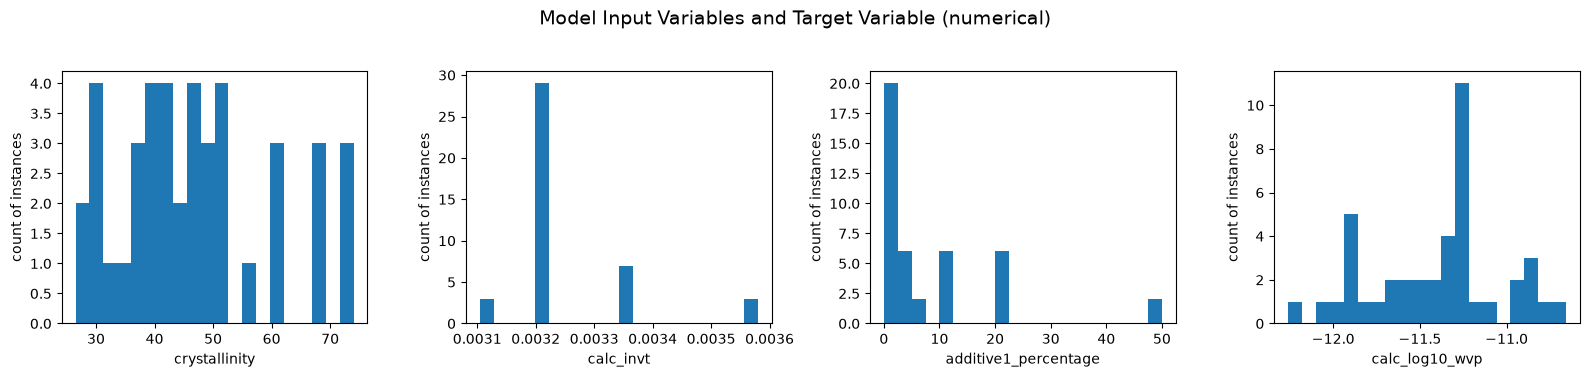

In [228]:
def plot_feature_distributions(
    df: pd.DataFrame,
    numerical_cols,
    categorical_cols,
    title_numeric="Model Input Variables and Target Variable (numerical)",
    title_categorical="Model Input Variables (categorical)",
    bins=20,
    max_cols_per_row=4,
    top_k_categories=20,   # cap bars for very high-cardinality cats
):
    # ---------- helper to grid-plot ----------
    def _grid_dims(n, max_cols):
        cols = min(max_cols, max(1, n))
        rows = int(math.ceil(n / cols))
        return rows, cols

    # ---------- NUMERICAL ----------
    if len(numerical_cols) > 0:
        n = len(numerical_cols)
        rows, cols = _grid_dims(n, max_cols_per_row)
        fig, axes = plt.subplots(rows, cols, figsize=(4.0*cols, 3.8*rows))
        axes = np.atleast_2d(axes)
        fig.suptitle(title_numeric, fontsize=14, y=0.98)

        for i, col in enumerate(numerical_cols):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            x = df[col].dropna().values
            ax.hist(x, bins=bins)
            ax.set_ylabel("count of instances")
            ax.set_xlabel(str(col))
            ax.grid(False)

        # hide any empty axes
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

    # ---------- CATEGORICAL ----------
    if len(categorical_cols) > 0:
        n = len(categorical_cols)
        rows, cols = _grid_dims(n, max_cols_per_row)
        fig, axes = plt.subplots(rows, cols, figsize=(4.6*cols, 4.0*rows))
        axes = np.atleast_2d(axes)
        fig.suptitle(title_categorical, fontsize=14, y=0.98)

        for i, col in enumerate(categorical_cols):
            r, c = divmod(i, cols)
            ax = axes[r, c]
            vc = (df[col].astype(str).replace("nan", np.nan)
                                 .value_counts(dropna=False)
                                 .head(top_k_categories))
            ax.bar(range(len(vc)), vc.values)
            ax.set_xticks(range(len(vc)))
            ax.set_xticklabels(vc.index.astype(str), rotation=30, ha="right", fontsize=9)
            ax.set_ylabel("count of instances")
            ax.set_xlabel(str(col))
            ax.grid(False)

        # hide any empty axes
        for j in range(n, rows*cols):
            r, c = divmod(j, cols)
            axes[r, c].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()


plot_feature_distributions(
    df_final,
    numerical_cols_lst,
    categorical_cols_lst,
    bins=20,
    max_cols_per_row=4,
    top_k_categories=20,
)

## Correlation matrix of numerical features

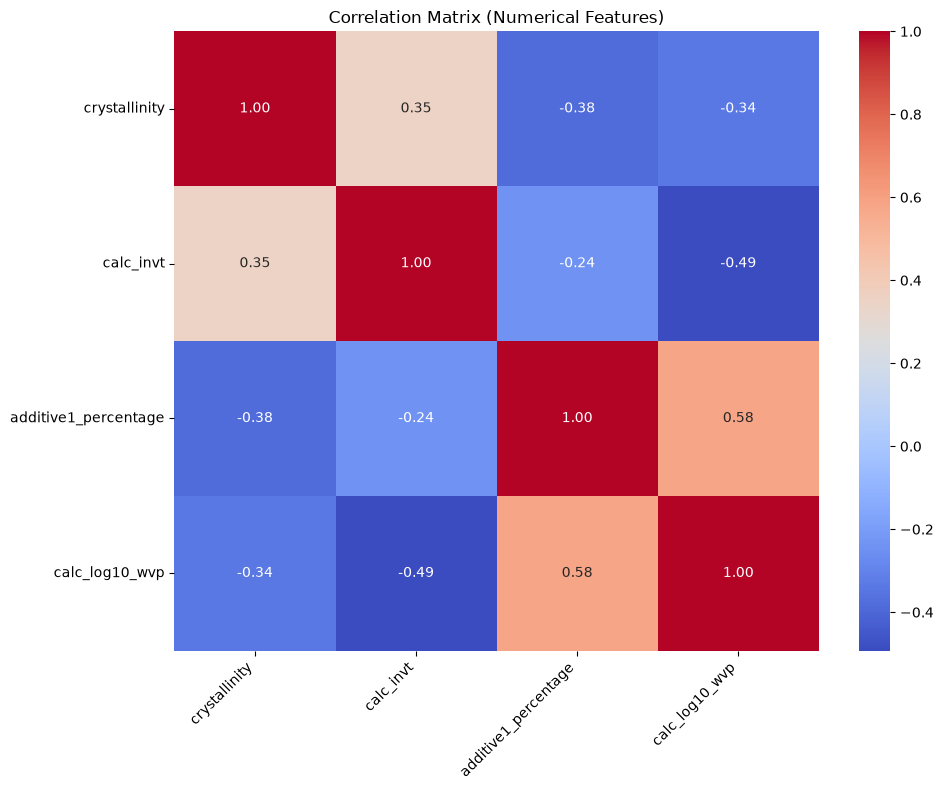

In [230]:
numerical_df = df_final[numerical_cols_lst]

# Compute correlation matrix
corr_matrix = numerical_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix (Numerical Features)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("correlation.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Train - test splitting

**Test set = held-out instances + rows chosen by the split algorithm**;

`split_method`: **'random'**, or **'kennard_stone'**

In [234]:
# Separate features and target
X = df_final.drop(columns=[target])
y = df_final[target]

In [236]:
split_method = 'kennard_stone'    # 'random' | 'kennard_stone' 
test_size = 0.2

def encode_for_distance(X):
    # one-hot + standardise 
    Xe = pd.get_dummies(X, columns=[c for c in categorical_cols_all if c in X.columns], dtype=float)
    return StandardScaler().fit_transform(Xe)

def kennard_stone_split(Z, n_train, y=None):
    D = cdist(Z, Z)
    if y is not None:     
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        Dy = cdist(y, y)
        D = D / D.max() + Dy / Dy.max()
    i, j = np.unravel_index(np.argmax(D), D.shape)          # the two most distant samples
    selected = [i, j]
    remaining = [k for k in range(len(Z)) if k not in selected]
    while len(selected) < n_train:                           # add the sample farthest from the selected set
        dmin = D[np.ix_(remaining, selected)].min(axis=1)
        k = remaining[int(np.argmax(dmin))]
        selected.append(k)
        remaining.remove(k)
    return np.sort(selected), np.sort(remaining)

def split_data(X, y, method='kennard_stone', n_test=3, seed=42):
    if method == 'random':
        return train_test_split(X, y, test_size=n_test, random_state=seed)
    n_train = len(X) - n_test
    Z = encode_for_distance(X)
    tr, te = kennard_stone_split(Z, n_train, y=(y.values if method == 'spxy' else None))
    return X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]

heldout_idx = heldout_idx.intersection(X.index)
n_test_total = int(math.ceil(test_size * len(X)))
n_test_split = max(n_test_total - len(heldout_idx), 1)     # rows to be chosen by the split algorithm

def make_split(method, seed=42):
    # split the pool (all rows except the held-out instances), then add the held-out instances to the test set
    Xp, yp = X.drop(index=heldout_idx), y.drop(index=heldout_idx)
    Xtr, Xte, ytr, yte = split_data(Xp, yp, method, n_test_split, seed)
    return Xtr, pd.concat([Xte, X.loc[heldout_idx]]), ytr, pd.concat([yte, y.loc[heldout_idx]])

X_train, X_test, y_train, y_test = make_split(split_method)
test_origin = pd.Series(np.where(X_test.index.isin(heldout_idx), 'held-out instance', 'split'), index=X_test.index)

print('Split method:', split_method)
print('Train set size:', X_train.shape, '\n Test set size', X_test.shape)
print('Train studies:', groups_all.loc[X_train.index].value_counts().sort_index().to_dict())
print('Test studies: ', groups_all.loc[X_test.index].value_counts().sort_index().to_dict())

Split method: kennard_stone
Train set size: (33, 3) 
 Test set size (9, 3)
Train studies: {'s002': 4, 's006': 11, 's007': 4, 's014': 4, 's020': 2, 's021': 8}
Test studies:  {'s006': 4, 's007': 1, 's014': 2, 's020': 1, 's021': 1}


## Check of the model features (train set only)

Association between the model features on the training rows: |Pearson r| (numeric-numeric), correlation ratio eta (categorical-numeric).

In [239]:
def corr_ratio(cat_s, num_s):
    # correlation ratio eta (0-1)
    m = num_s.mean(); sst = ((num_s - m) ** 2).sum()
    ssb = sum(len(v) * (v.mean() - m) ** 2 for _, v in num_s.groupby(cat_s))
    return float(np.sqrt(ssb / sst)) if sst > 0 else 0.0

cat_f = [c for c in X_train.columns if c in categorical_cols_all]
num_f = [c for c in X_train.columns if c not in cat_f]
for c in cat_f:
    for n_ in num_f:
        print(f'eta({c}, {n_}) = {corr_ratio(X_train[c], X_train[n_]):.2f}')
print('\nrelation with the target (train rows):')
for c in cat_f:
    print(f'  eta({c}, target) = {corr_ratio(X_train[c], y_train):.2f}')
for n_ in num_f:
    print(f'  |Pearson r|({n_}, target) = {abs(np.corrcoef(X_train[n_], y_train)[0, 1]):.2f}')


relation with the target (train rows):
  |Pearson r|(crystallinity, target) = 0.44
  |Pearson r|(calc_invt, target) = 0.58
  |Pearson r|(additive1_percentage, target) = 0.55


## FAMD + IQR outlier detection - only on the Train set (if applied)

**Test = 1:** No exclusion (default)
**Test = 2:** +-3 IQR   **Test = 3:** +-7 IQR

In [242]:
test = 1

# Detect outliers using IQR
def detect_iqr_outliers(df, alpha):
    outlier_indices = set()
    for col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - alpha * IQR
        upper_bound = Q3 + alpha * IQR
        outliers_col = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index
        outlier_indices.update(outliers_col)
    return list(outlier_indices)

if test in (2, 3):
    alpha = 3 if test == 2 else 7
    famd = FAMD(n_components=4, random_state=42)
    X_train_famd_df = famd.fit_transform(X_train)
    X_train_famd_df.columns = [f'Comp{i+1}' for i in range(X_train_famd_df.shape[1])]
    outlier_idx_train = detect_iqr_outliers(X_train_famd_df, alpha)
    X_train_clean = X_train.drop(index=outlier_idx_train)
    y_train_clean = y_train.drop(index=outlier_idx_train)
    print("IQR outlier detection APPLIED with +-", alpha)
else:
    X_train_clean = X_train
    y_train_clean = y_train
    print("IQR outlier detection SKIPPED")

print(f"Original data shape: {X_train.shape}")
print(f"Cleaned data shape: {X_train_clean.shape}")

IQR outlier detection SKIPPED
Original data shape: (33, 3)
Cleaned data shape: (33, 3)


In [244]:
X_train_clean.tail()

,crystallinity,calc_invt,additive1_percentage
68,69.0,0.003354,0.0
69,69.0,0.003104,0.0
70,62.0,0.003580,0.0
71,62.0,0.003354,0.0
72,62.0,0.003104,0.0


## One-hot encoding

In [247]:
X_train = X_train_clean.copy()

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop=None)

if categorical_cols_lst:
    ohe.fit(X_train[categorical_cols_lst])

    # Transform
    X_train_ohe = ohe.transform(X_train[categorical_cols_lst])
    X_test_ohe = ohe.transform(X_test[categorical_cols_lst])

    # Convert to DataFrame with proper column names
    ohe_columns = ohe.get_feature_names_out(categorical_cols_lst)
    X_train_ohe_df = pd.DataFrame(X_train_ohe, columns=ohe_columns, index=X_train.index)
    X_test_ohe_df = pd.DataFrame(X_test_ohe, columns=ohe_columns, index=X_test.index)
else:
    ohe_columns = []
    X_train_ohe_df = pd.DataFrame(index=X_train.index)
    X_test_ohe_df = pd.DataFrame(index=X_test.index)

In [249]:
# combine
X_train_final = pd.concat([X_train.drop(columns=categorical_cols_lst), X_train_ohe_df], axis=1)
X_test_final = pd.concat([X_test.drop(columns=categorical_cols_lst), X_test_ohe_df], axis=1)

# study id of each training row, grouped cross-validation (whole studies are left out in every fold)
groups_train = groups_all.loc[X_train_final.index]
n_splits = int(min(3, groups_train.nunique()))
cv = GroupKFold(n_splits=n_splits)

print(f"X_train_final shape: {X_train_final.shape}")
print(f"X_test_final shape: {X_test_final.shape}")
print(f"Grouped CV: {n_splits} folds over {groups_train.nunique()} studies")

X_train_final shape: (33, 3)
X_test_final shape: (9, 3)
Grouped CV: 3 folds over 6 studies


## RF and Gaussian Process regression

In [252]:
n_feat = X_train_final.shape[1]

gp_kernel = (C(0.3) * RBF(length_scale=np.ones(n_feat), length_scale_bounds=(0.3, 30))   # smooth non-linear part (one length scale per feature)
             + C(0.1) * DotProduct(sigma_0=1.0)                                          # linear part
             + WhiteKernel(0.05, (1e-4, 1)))                                             # noise

models = {
    'Random Forest': RandomForestRegressor(
        n_estimators=500, max_depth=None, min_samples_split=2, min_samples_leaf=1,
        random_state=42, n_jobs=-1),
    'Gaussian process': make_pipeline(
        StandardScaler(),
        TransformedTargetRegressor(
            GaussianProcessRegressor(gp_kernel, n_restarts_optimizer=2, random_state=0),
            transformer=StandardScaler()))
 }

preds = {}
for name, mdl in models.items():
    mdl.fit(X_train_final, y_train_clean)
    preds[name] = {
        'train': mdl.predict(X_train_final),
        'test': mdl.predict(X_test_final),
    }

In [253]:
y_test = y_test.copy()

def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    r = pearsonr(y_true, y_pred)[0] if (len(y_true) > 2 and np.std(y_pred) > 0) else np.nan
    return {
        'R^2 (log)': r2_score(y_true, y_pred),
        'Pearson r (log)': r,
        'RMSE (log)': root_mean_squared_error(y_true, y_pred),
        'MAE (log)': mean_absolute_error(y_true, y_pred),
    }

metrics = []
for name in models:
    for ds, y_true in (('Train', y_train_clean), ('Test', y_test)):
        m = compute_metrics(y_true, preds[name][ds.lower()])
        metrics.append([name, ds, m['R^2 (log)'], m['Pearson r (log)'], m['RMSE (log)'], m['MAE (log)']])

In [254]:
metrics_df = pd.DataFrame(
    metrics,
    columns=['Model', 'Dataset', 'R^2 (log)', 'Pearson r (log)', 'RMSE (log)', 'MAE (log)']
)

print(metrics_df.round(3).to_string(index=False))

           Model Dataset  R^2 (log)  Pearson r (log)  RMSE (log)  MAE (log)
   Random Forest   Train      0.943            0.979       0.084      0.067
   Random Forest    Test      0.565            0.876       0.279      0.217
Gaussian process   Train      0.874            0.940       0.125      0.089
Gaussian process    Test      0.632            0.912       0.256      0.216


## Grid search

Hyper-parameters are selected with **grouped CV** (`KFold` on `Study_id`), i.e. each fold predicts a study the model has not seen.
The selection metric is RMSE.

In [259]:
from sklearn.model_selection import cross_validate

tuned = {}     # best estimators
summaries = {} # summary tables

def run_grid(name, estimator, param_grid):
    gs = GridSearchCV(estimator, param_grid, cv=cv,
                      scoring='neg_root_mean_squared_error', n_jobs=1, verbose=0)
    gs.fit(X_train_final, y_train_clean, groups=groups_train)
    best = gs.best_estimator_

    y_tr = best.predict(X_train_final)
    y_te = best.predict(X_test_final)

    # one CV pass (RMSE only)
    cvres = cross_validate(best, X_train_final, y_train_clean, cv=cv, groups=groups_train,
                           scoring='neg_root_mean_squared_error')
    cv_rmse = -cvres['test_score']

    summary = pd.DataFrame({
        'Metric': ['Train R^2', 'Test R^2', 'CV Mean RMSE (log)', 'CV SD RMSE (log)',
                   'Train Pearson r', 'Test Pearson r', 'Train RMSE (log)', 'Test RMSE (log)'],
        f'{name} (Tuned)': [
            r2_score(y_train_clean, y_tr), r2_score(y_test, y_te),
            cv_rmse.mean(), cv_rmse.std(),
            pearsonr(y_train_clean, y_tr)[0], pearsonr(y_test, y_te)[0],
            root_mean_squared_error(y_train_clean, y_tr), root_mean_squared_error(y_test, y_te),
        ]
    })
    tuned[name] = best
    summaries[name] = summary
    preds[f'{name} (tuned)'] = {'train': y_tr, 'test': y_te}
    print(f"Best parameters found ({name}): {gs.best_params_}")
    print(f"Best CV RMSE (log): {-gs.best_score_:.3f}")
    print(summary.round(3).to_string(index=False))
    return best

## RF

In [262]:
param_grid = {
    'n_estimators': [500], # 200, 500],
    'max_depth': [None], # 3
    'min_samples_split': [2],
    'min_samples_leaf': [2], # 4,6
}
best_rf = run_grid('Random Forest', RandomForestRegressor(random_state=42, n_jobs=1), param_grid)
best_params = best_rf.get_params()

Best parameters found (Random Forest): {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 500}
Best CV RMSE (log): 0.415
            Metric  Random Forest (Tuned)
         Train R^2                  0.845
          Test R^2                  0.595
CV Mean RMSE (log)                  0.415
  CV SD RMSE (log)                  0.064
   Train Pearson r                  0.931
    Test Pearson r                  0.884
  Train RMSE (log)                  0.139
   Test RMSE (log)                  0.269


In [264]:
hold_studies = ['S002', 'S007', 'S020']
g = groups_train.astype(str).str.lower().to_numpy()         
splits = [(np.where(g != s.lower())[0], np.where(g == s.lower())[0]) for s in hold_studies]

# mean of the per-study RMSEs
fold_rmse = -cross_val_score(best_rf, X_train_final, y_train_clean, cv=splits,
                             scoring='neg_root_mean_squared_error')
grouped_rmse = fold_rmse.mean()

# pooled RMSE over the held-out rows
y_arr = np.asarray(y_train_clean)
err, err_base = [], []
for tr, te in splits:
    m = clone(best_rf).fit(X_train_final.iloc[tr], y_arr[tr])
    err.append(y_arr[te] - m.predict(X_train_final.iloc[te]))
    err_base.append(y_arr[te] - y_arr[tr].mean())
pooled = np.sqrt(np.mean(np.concatenate(err) ** 2))
pooled_base = np.sqrt(np.mean(np.concatenate(err_base) ** 2))

print('Grouped-CV RMSE per left-out study:', dict(zip(hold_studies, fold_rmse.round(3))))
print(f"Grouped-CV RMSE (unseen study, S002/S007/S020): mean of folds {grouped_rmse:.3f} | pooled {pooled:.3f} | mean predictor {pooled_base:.3f}")

Grouped-CV RMSE per left-out study: {'S002': np.float64(0.375), 'S007': np.float64(0.161), 'S020': np.float64(0.242)}
Grouped-CV RMSE (unseen study, S002/S007/S020): mean of folds 0.259 | pooled 0.280 | mean predictor 0.195


In [268]:
study = df_loss.loc[X_train_final.index, 'study_id'].reset_index(drop=True)
sample = df_loss.loc[X_train_final.index, 'instance'].reset_index(drop=True)
study_sample = study.astype(str) + '_' + sample.astype(str)      # unique id: instance numbers repeat across studies

class MultiSampleLOIO:
    """Leave-one-instance-out, only for instances whose study has >1 sample."""
    def __init__(self, study, sample):
        self.study, self.sample = np.asarray(study), np.asarray(sample)
        n = pd.Series(self.sample).groupby(self.study).nunique()
        self.multi = set(n[n > 1].index)
        self.instances = [s for s in pd.unique(self.sample) if self.study[self.sample == s][0] in self.multi]
    def split(self, X=None, y=None, groups=None):
        for inst in self.instances:
            yield np.where(self.sample != inst)[0], np.where(self.sample == inst)[0]

cv_loio = MultiSampleLOIO(study, study_sample)

Xr, yr = X_train_final.reset_index(drop=True), np.asarray(y_train_clean)
mask = np.zeros(len(yr), bool); oof = np.full(len(yr), np.nan)
for tr, te in cv_loio.split():
    m = clone(best_rf).fit(Xr.iloc[tr], yr[tr])
    oof[te] = m.predict(Xr.iloc[te]); mask[te] = True                 # no clipping

print(f"LOIO: n={mask.sum()}  R2={r2_score(yr[mask], oof[mask]):.3f}  RMSE={root_mean_squared_error(yr[mask], oof[mask]):.3f}  "
      f"MAE={mean_absolute_error(yr[mask], oof[mask]):.3f}  r={pearsonr(yr[mask], oof[mask])[0]:.3f}")

LOIO: n=33  R2=0.461  RMSE=0.259  MAE=0.202  r=0.679


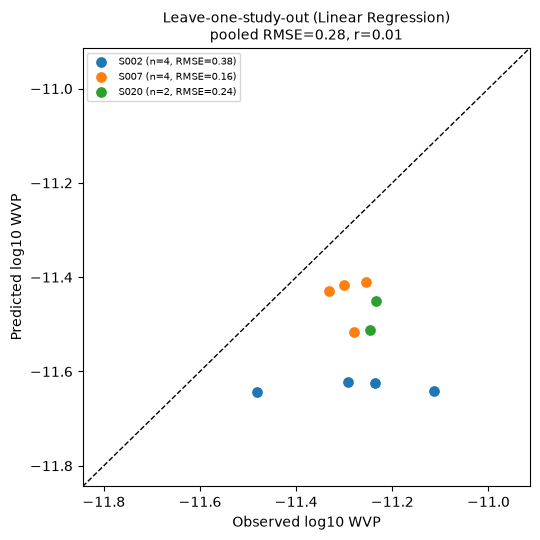

In [159]:
hold_studies = ['S002', 'S007', 'S020']
g = np.asarray(groups_train).astype(str)
y_obs_all = np.asarray(y_train_clean)

obs, hat, lab = [], [], []
for s in hold_studies:
    te = np.where(np.char.lower(g) == s.lower())[0]
    tr = np.where(np.char.lower(g) != s.lower())[0]            # every other study stays in training
    m = clone(best_rf).fit(X_train_final.iloc[tr], y_obs_all[tr])
    obs.append(y_obs_all[te]); hat.append(m.predict(X_train_final.iloc[te])); lab.append(np.full(len(te), s))
y_obs, y_hat, studies = np.concatenate(obs), np.concatenate(hat), np.concatenate(lab)

rmse_all = np.sqrt(np.mean((y_obs - y_hat) ** 2))
r_all = np.corrcoef(y_obs, y_hat)[0, 1]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for s in hold_studies:
    m = studies == s
    ax.scatter(y_obs[m], y_hat[m], s=45, label=f"{s} (n={m.sum()}, RMSE={np.sqrt(np.mean((y_obs[m]-y_hat[m])**2)):.2f})")
lims = [min(y_obs.min(), y_hat.min()) - 0.2, max(y_obs.max(), y_hat.max()) + 0.2]
ax.plot(lims, lims, 'k--', lw=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Observed log10 WVP'); ax.set_ylabel('Predicted log10 WVP')
ax.set_title(f'Leave-one-study-out (Linear Regression)\npooled RMSE={rmse_all:.2f}, r={r_all:.2f}', fontsize=10)
ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
plt.savefig("pha_wvp_rf_loo.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Plot results - RF

In [101]:
# Predictions
y_train_pred_grid = best_rf.predict(X_train_final)
y_test_pred_grid = best_rf.predict(X_test_final)

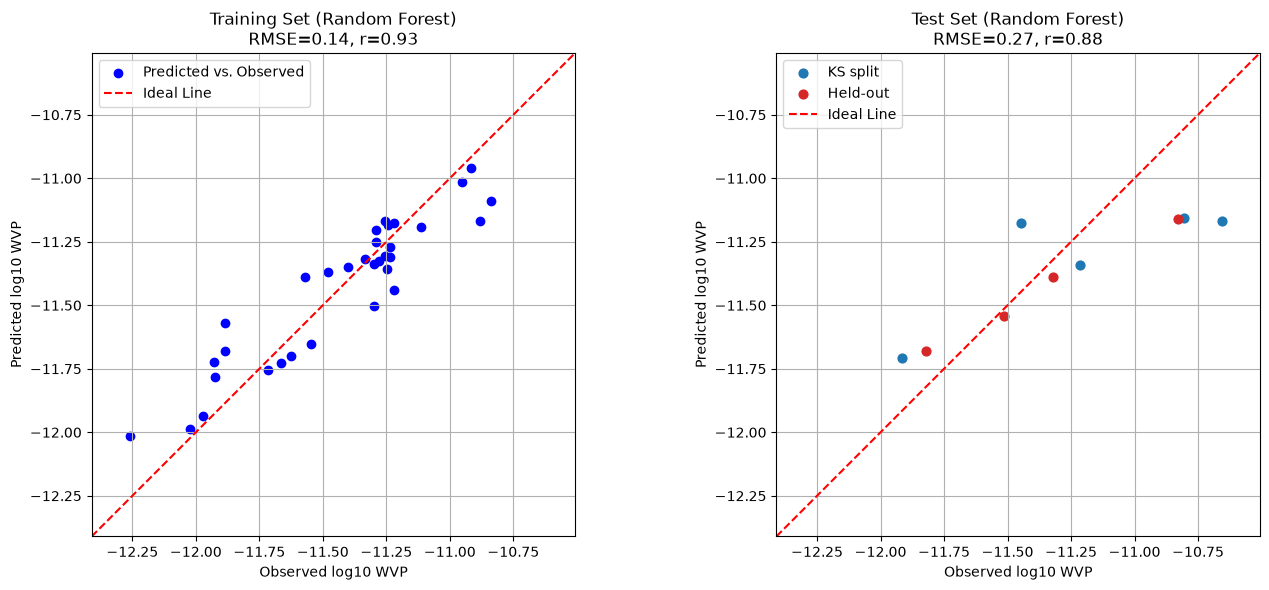

In [134]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # width doubled for 2 plots

# common axis limits so both panels are comparable
all_vals = np.concatenate([y_train_clean, y_test, y_train_pred_grid, y_test_pred_grid])
lo, hi = all_vals.min() - 0.15, all_vals.max() + 0.15

# Plot Training Set
axes[0].scatter(y_train_clean, y_train_pred_grid, color='blue', label='Predicted vs. Observed')
axes[0].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[0].set_xlabel('Observed log10 WVP')
axes[0].set_ylabel('Predicted log10 WVP')
axes[0].set_title(f'Training Set (Random Forest)\nRMSE={root_mean_squared_error(y_train_clean, y_train_pred_grid):.2f}, '
                  f'r={pearsonr(y_train_clean, y_train_pred_grid)[0]:.2f}')
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi); axes[0].set_aspect('equal')
axes[0].legend()
axes[0].grid(True)

# Plot Test Set
# axes[1].scatter(y_test, y_test_pred_grid4, color='green', label='Predicted vs. Observed')
held_mask = (test_origin.to_numpy() == 'held-out instance')     # test_origin is indexed like X_test
y_te = np.asarray(y_test)

# replace the test-set scatter (axes[1]) in your plotting cell
axes[1].scatter(y_te[~held_mask], y_test_pred_grid[~held_mask], color='tab:blue', s=40, label='KS split')
axes[1].scatter(y_te[held_mask], y_test_pred_grid[held_mask], color='tab:red', s=40, label='Held-out')

axes[1].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[1].set_xlabel('Observed log10 WVP')
axes[1].set_ylabel('Predicted log10 WVP')
axes[1].set_title(f'Test Set (Random Forest)\nRMSE={root_mean_squared_error(y_test, y_test_pred_grid):.2f}, '
                  f'r={pearsonr(y_test, y_test_pred_grid)[0]:.2f}')
axes[1].set_xlim(lo, hi); axes[1].set_ylim(lo, hi); axes[1].set_aspect('equal')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("pha_wvp_rf_tuned.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Plot RMSE w.r.t No of trees

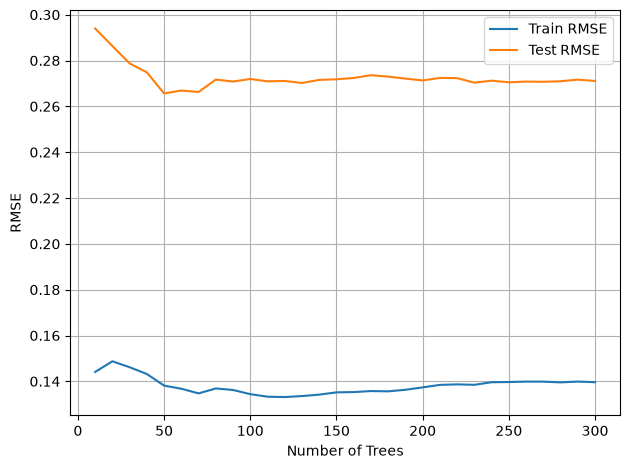

In [107]:
train_rmse = []
test_rmse = []

n_estimators_range = range(10, 301, 10)

for n in n_estimators_range:
    rf_n = RandomForestRegressor(
        n_estimators=n,
        max_depth=best_params['max_depth'],
        min_samples_split=best_params['min_samples_split'],
        min_samples_leaf=best_params['min_samples_leaf'],
        random_state=42,
        n_jobs=-1
    )
    rf_n.fit(X_train_final, y_train_clean)

    train_rmse.append(root_mean_squared_error(y_train_clean, rf_n.predict(X_train_final)))
    test_rmse.append(root_mean_squared_error(y_test, rf_n.predict(X_test_final)))

plt.figure()
plt.plot(n_estimators_range, train_rmse, label="Train RMSE")
plt.plot(n_estimators_range, test_rmse, label="Test RMSE")
plt.xlabel("Number of Trees")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("pha_wvp_rf_rmse.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Feature importance - RF

In [169]:
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_train_final)     # array shape: (n_samples, n_features)
base_value = explainer.expected_value

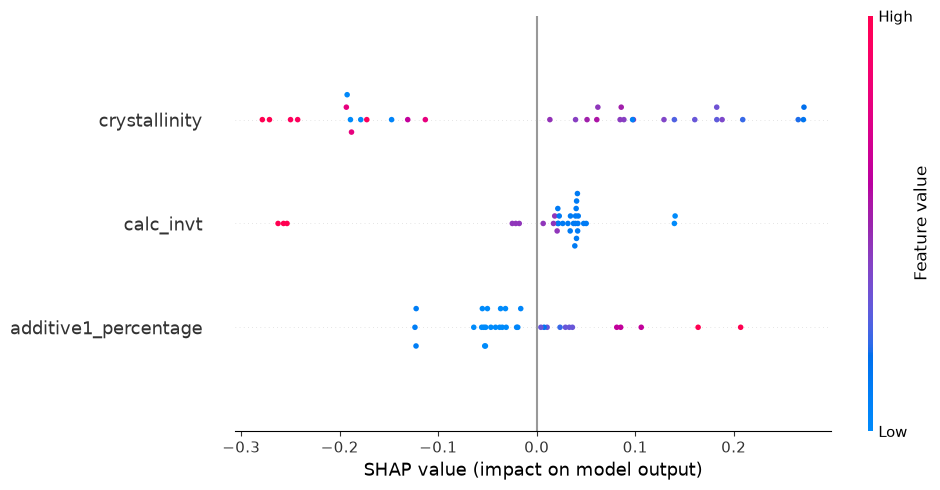

In [171]:
shap.summary_plot(
    shap_values,
    X_train_final,
    show=False,
    plot_size=(10, 5)
)

plt.tight_layout()
plt.savefig("pha_wvp_rf_shap.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## GP

In [270]:
# GP: the kernel parameters are fitted by marginal likelihood, so the grid is empty
best_gp = run_grid('Gaussian process', models['Gaussian process'], {})

Best parameters found (Gaussian process): {}
Best CV RMSE (log): 0.466
            Metric  Gaussian process (Tuned)
         Train R^2                     0.874
          Test R^2                     0.632
CV Mean RMSE (log)                     0.466
  CV SD RMSE (log)                     0.042
   Train Pearson r                     0.940
    Test Pearson r                     0.912
  Train RMSE (log)                     0.125
   Test RMSE (log)                     0.256


In [272]:
# mean of the per-study RMSEs
fold_rmse = -cross_val_score(best_gp, X_train_final, y_train_clean, cv=splits,
                             scoring='neg_root_mean_squared_error')
grouped_rmse = fold_rmse.mean()

# pooled RMSE over the held-out rows
y_arr = np.asarray(y_train_clean)
err, err_base = [], []
for tr, te in splits:
    m = clone(best_gp).fit(X_train_final.iloc[tr], y_arr[tr])
    err.append(y_arr[te] - m.predict(X_train_final.iloc[te]))
    err_base.append(y_arr[te] - y_arr[tr].mean())
pooled = np.sqrt(np.mean(np.concatenate(err) ** 2))
pooled_base = np.sqrt(np.mean(np.concatenate(err_base) ** 2))

print('Grouped-CV RMSE per left-out study:', dict(zip(hold_studies, fold_rmse.round(3))))
print(f"Grouped-CV RMSE (unseen study, S002/S007/S020): mean of folds {grouped_rmse:.3f} | pooled {pooled:.3f} | mean predictor {pooled_base:.3f}")

Grouped-CV RMSE per left-out study: {'S002': np.float64(0.449), 'S007': np.float64(0.069), 'S020': np.float64(0.203)}
Grouped-CV RMSE (unseen study, S002/S007/S020): mean of folds 0.240 | pooled 0.301 | mean predictor 0.195


In [274]:
for tr, te in cv_loio.split():
    m = clone(best_gp).fit(Xr.iloc[tr], yr[tr])
    oof[te] = m.predict(Xr.iloc[te]); mask[te] = True                 # no clipping

print(f"LOIO: n={mask.sum()}  R2={r2_score(yr[mask], oof[mask]):.3f}  RMSE={root_mean_squared_error(yr[mask], oof[mask]):.3f}  "
      f"MAE={mean_absolute_error(yr[mask], oof[mask]):.3f}  r={pearsonr(yr[mask], oof[mask])[0]:.3f}")

LOIO: n=33  R2=0.479  RMSE=0.254  MAE=0.188  r=0.694


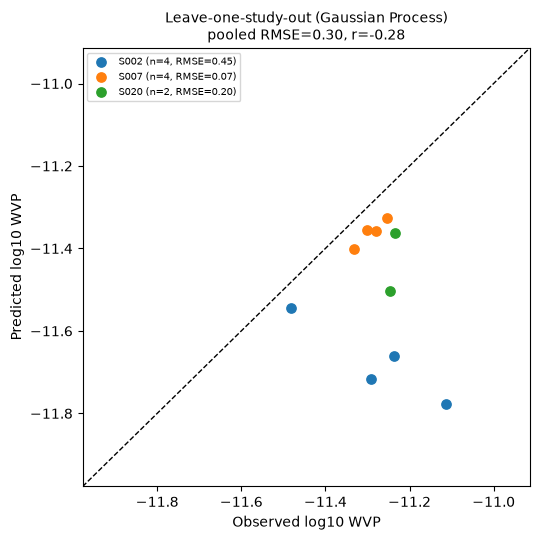

In [118]:
hold_studies = ['S002', 'S007', 'S020']
g = np.asarray(groups_train).astype(str)
y_obs_all = np.asarray(y_train_clean)

obs, hat, lab = [], [], []
for s in hold_studies:
    te = np.where(np.char.lower(g) == s.lower())[0]
    tr = np.where(np.char.lower(g) != s.lower())[0]            # every other study stays in training
    m = clone(best_gp).fit(X_train_final.iloc[tr], y_obs_all[tr])
    obs.append(y_obs_all[te]); hat.append(m.predict(X_train_final.iloc[te])); lab.append(np.full(len(te), s))
y_obs, y_hat, studies = np.concatenate(obs), np.concatenate(hat), np.concatenate(lab)

rmse_all = np.sqrt(np.mean((y_obs - y_hat) ** 2))
r_all = np.corrcoef(y_obs, y_hat)[0, 1]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for s in hold_studies:
    m = studies == s
    ax.scatter(y_obs[m], y_hat[m], s=45, label=f"{s} (n={m.sum()}, RMSE={np.sqrt(np.mean((y_obs[m]-y_hat[m])**2)):.2f})")
lims = [min(y_obs.min(), y_hat.min()) - 0.2, max(y_obs.max(), y_hat.max()) + 0.2]
ax.plot(lims, lims, 'k--', lw=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Observed log10 WVP'); ax.set_ylabel('Predicted log10 WVP')
ax.set_title(f'Leave-one-study-out (Gaussian Process)\npooled RMSE={rmse_all:.2f}, r={r_all:.2f}', fontsize=10)
ax.legend(fontsize=7, loc='upper left')
plt.tight_layout()
plt.savefig("pha_wvp_gp_loo.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

In [120]:
# Predictions
y_train_pred_grid2 = best_gp.predict(X_train_final)
y_test_pred_grid2 = best_gp.predict(X_test_final)

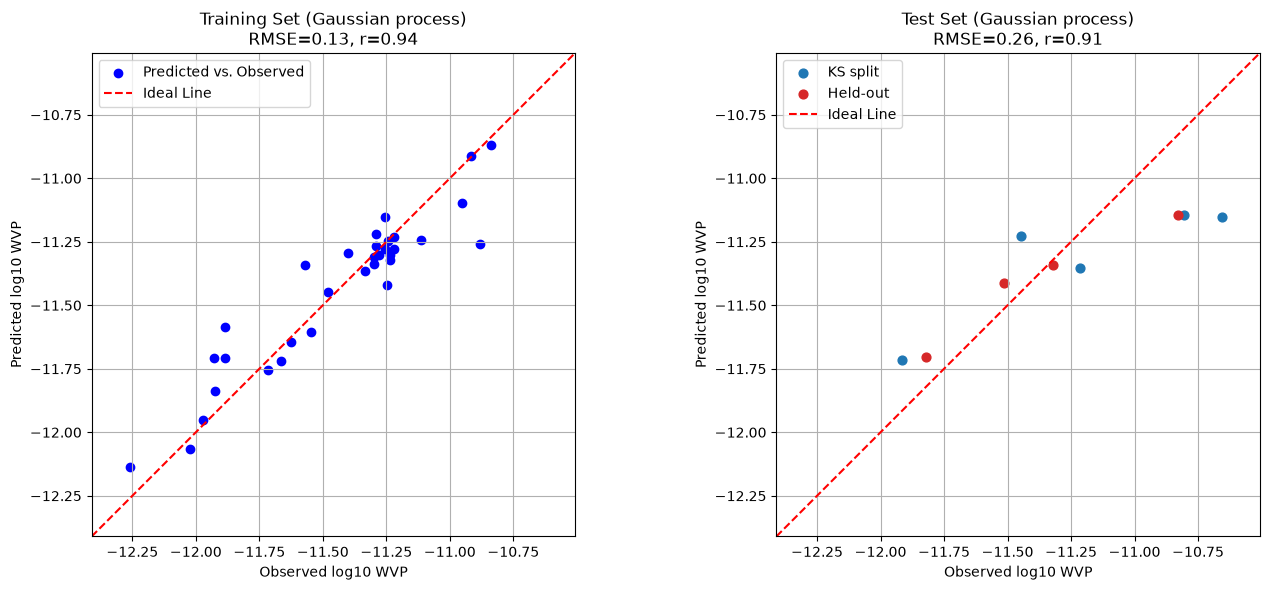

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # width doubled for 2 plots

# common axis limits so both panels are comparable
all_vals = np.concatenate([y_train_clean, y_test, y_train_pred_grid2, y_test_pred_grid2])
lo, hi = all_vals.min() - 0.15, all_vals.max() + 0.15

# Plot Training Set
axes[0].scatter(y_train_clean, y_train_pred_grid2, color='blue', label='Predicted vs. Observed')
axes[0].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[0].set_xlabel('Observed log10 WVP')
axes[0].set_ylabel('Predicted log10 WVP')
axes[0].set_title(f'Training Set (Gaussian process)\nRMSE={root_mean_squared_error(y_train_clean, y_train_pred_grid2):.2f}, '
                  f'r={pearsonr(y_train_clean, y_train_pred_grid2)[0]:.2f}')
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi); axes[0].set_aspect('equal')
axes[0].legend()
axes[0].grid(True)

# Plot Test Set
# axes[1].scatter(y_test, y_test_pred_grid4, color='green', label='Predicted vs. Observed')
held_mask = (test_origin.to_numpy() == 'held-out instance')     # test_origin is indexed like X_test
y_te = np.asarray(y_test)

# replace the test-set scatter (axes[1]) in your plotting cell
axes[1].scatter(y_te[~held_mask], y_test_pred_grid2[~held_mask], color='tab:blue', s=40, label='KS split')
axes[1].scatter(y_te[held_mask], y_test_pred_grid2[held_mask], color='tab:red', s=40, label='Held-out')

axes[1].plot([lo, hi], [lo, hi], linestyle='--', color='red', label='Ideal Line')
axes[1].set_xlabel('Observed log10 WVP')
axes[1].set_ylabel('Predicted log10 WVP')
axes[1].set_title(f'Test Set (Gaussian process)\nRMSE={root_mean_squared_error(y_test, y_test_pred_grid2):.2f}, '
                  f'r={pearsonr(y_test, y_test_pred_grid2)[0]:.2f}')
axes[1].set_xlim(lo, hi); axes[1].set_ylim(lo, hi); axes[1].set_aspect('equal')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("pha_wvp_gp_tuned.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

100%|██████████| 33/33 [00:00<00:00, 93.90it/s]


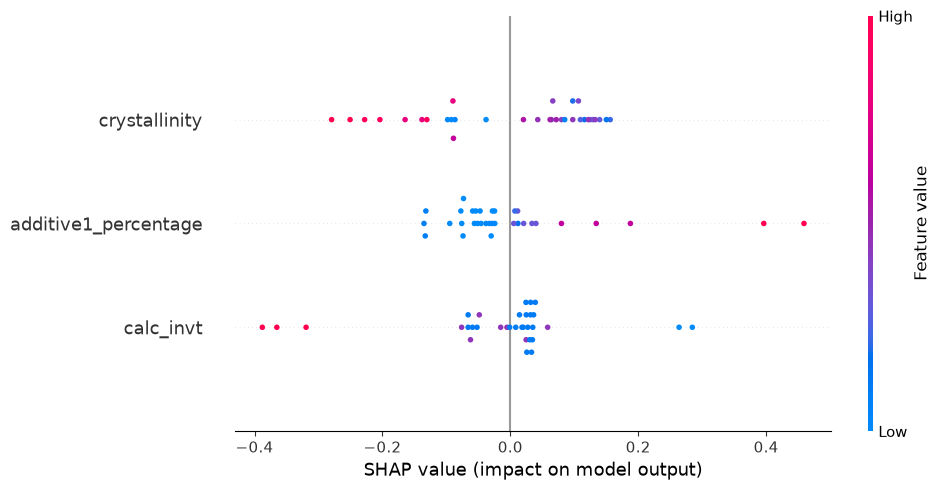

In [165]:
import shap
cols = X_train_final.columns
predict_fn = lambda X: best_gp.predict(pd.DataFrame(X, columns=cols))      # wrapper

background = shap.kmeans(X_train_final, 10)                                # 10 representative training rows
explainer = shap.KernelExplainer(predict_fn, background)
shap_values = explainer.shap_values(X_train_final, nsamples=200)           # or X_test_final

shap.summary_plot(shap_values, X_train_final,show=False,
    plot_size=(10, 5)
)

plt.tight_layout()
plt.savefig("pha_wvp_gp_shap.tiff", format="tiff", dpi=300, bbox_inches="tight")
plt.show()

## Test set - predictions per instance

In [142]:
final_models = ['Random Forest', 'Gaussian process']

df_test_tbl = df_loss.loc[X_test.index, ['study_id', 'instance']].copy()
df_test_tbl['origin'] = test_origin
df_test_tbl['observed'] = y_test
for n in final_models:
    df_test_tbl[n] = preds[f'{n} (tuned)']['test']
df_test_tbl.sort_values(['origin', 'study_id', 'instance']).round(3)

,study_id,instance,origin,observed,Random Forest,Gaussian process
24,S006,15,held-out instance,-10.828,-11.159,-11.145
27,S007,3,held-out instance,-11.322,-11.390,-11.340
39,S014,5,held-out instance,-11.821,-11.682,-11.703
66,S021,3,held-out instance,-11.515,-11.543,-11.414
19,S006,10,split,-11.445,-11.177,-11.227
20,S006,11,split,-10.807,-11.158,-11.143
22,S006,13,split,-10.657,-11.168,-11.152
37,S014,3,split,-11.917,-11.707,-11.714
62,S020,2,split,-11.217,-11.339,-11.352


## Summary - all models

In [146]:
final_models = ['Random Forest', 'Gaussian process']   

hold_studies = ['S002', 'S007', 'S020']
g = np.asarray(groups_train).astype(str)
y_arr = np.asarray(y_train_clean)
held_mask = (test_origin.to_numpy() == 'held-out instance')

def grouped_pooled_rmse(estimator):
    # leave S002, S007, S020 out one at a time (all other studies stay in training); pooled RMSE over the 10 rows
    err = []
    for s in hold_studies:
        te = np.where(np.char.lower(g) == s.lower())[0]
        tr = np.where(np.char.lower(g) != s.lower())[0]
        if estimator is None:                                   # mean baseline
            pred = np.full(len(te), y_arr[tr].mean())
        else:
            pred = clone(estimator).fit(X_train_final.iloc[tr], y_arr[tr]).predict(X_train_final.iloc[te])
        err.append(y_arr[te] - pred)
    return np.sqrt(np.mean(np.concatenate(err) ** 2))

rows = []
for name in final_models:
    key = name if name == 'Mean baseline' else f'{name} (tuned)'
    for ds, yt, yp in (('Train', y_train_clean, preds[key]['train']),
                       ('Test', y_test, preds[key]['test'])):
        m = compute_metrics(yt, yp)
        row = [name, ds, len(yt), m['R^2 (log)'], m['Pearson r (log)'], m['RMSE (log)'], m['MAE (log)']]
        if ds == 'Test':      # test RMSE split by the origin of the rows
            yt_a, yp_a = np.asarray(yt), np.asarray(yp)
            row += [root_mean_squared_error(yt_a[held_mask], yp_a[held_mask]),
                    root_mean_squared_error(yt_a[~held_mask], yp_a[~held_mask])]
            row.append(grouped_pooled_rmse(None if name == 'Mean baseline' else tuned[name]))
        else:
            row += [np.nan, np.nan, np.nan]
        rows.append(row)

summary_all = pd.DataFrame(rows, columns=['Model', 'Dataset', 'n', 'R^2 (log)', 'Pearson r (log)', 'RMSE (log)', 'MAE (log)',
                                          'RMSE held-out inst.', 'RMSE split rows', 'Grouped RMSE'])
summary_all['Mean fold error'] = 10 ** summary_all['MAE (log)']   # typical multiplicative error in WVP
print(summary_all.round(3).to_string(index=False))

           Model Dataset  n  R^2 (log)  Pearson r (log)  RMSE (log)  MAE (log)  RMSE held-out inst.  RMSE split rows  Grouped RMSE  Mean fold error
   Random Forest   Train 33      0.845            0.931       0.139      0.111                  NaN              NaN           NaN            1.290
   Random Forest    Test  9      0.595            0.884       0.269      0.226                0.183            0.321         0.280            1.681
Gaussian process   Train 33      0.874            0.940       0.125      0.089                  NaN              NaN           NaN            1.227
Gaussian process    Test  9      0.632            0.912       0.256      0.216                0.177            0.305         0.301            1.644


## Comparison of splitting algorithms

The hyper-parameters found above are re-used and every model is refitted for each split. The test set always contains the same held-out instances plus the rows chosen by the split algorithm.

In [151]:
cmp_models = ['Random Forest', 'Gaussian process']

def encode_pair(Xtr, Xte, feats):
    cat = [c for c in feats if c in categorical_cols_all]
    num = [c for c in feats if c not in cat]
    if cat:
        o = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(Xtr[cat])
        mk = lambda Xa: pd.concat([Xa[num], pd.DataFrame(o.transform(Xa[cat]), columns=o.get_feature_names_out(cat), index=Xa.index)], axis=1)
    else:
        mk = lambda Xa: Xa[num].copy()
    return mk(Xtr), mk(Xte)

def fit_eval(Xtr, ytr, Xte, yte, feature_set='selected'):
    feats = list(Xtr.columns)
    Etr, Ete = encode_pair(Xtr, Xte, feats)
    out = {}
    for n in cmp_models:
        mdl = clone(tuned[n]).fit(Etr, ytr)
        p = mdl.predict(Ete)
        out[n] = dict(R2=r2_score(yte, p), r=pearsonr(yte, p)[0], RMSE=root_mean_squared_error(yte, p),
                      R2_train=r2_score(ytr, mdl.predict(Etr)))
    return out, feats

rows = []
for method in ['random', 'kennard_stone', 'spxy']:
    Xtr, Xte, ytr, yte = make_split(method)
    print(f"{method:14s} test studies: {groups_all.loc[Xte.index].value_counts().sort_index().to_dict()} | SD y train/test: {ytr.std():.2f}/{yte.std():.2f}")
    res_m, feats_m = fit_eval(Xtr, ytr, Xte, yte)
    for n, m in res_m.items():
        rows.append([method, n, m['R2'], m['r'], m['RMSE']])

split_cmp = pd.DataFrame(rows, columns=['Split', 'Model', 'Test R^2', 'Test Pearson r', 'Test RMSE (log)'])
print(split_cmp.round(3).to_string(index=False))

random         test studies: {'s006': 3, 's007': 1, 's014': 1, 's021': 4} | SD y train/test: 0.36/0.40
kennard_stone  test studies: {'s006': 4, 's007': 1, 's014': 2, 's020': 1, 's021': 1} | SD y train/test: 0.36/0.45
spxy           test studies: {'s006': 2, 's007': 2, 's014': 2, 's020': 2, 's021': 1} | SD y train/test: 0.40/0.33
        Split            Model  Test R^2  Test Pearson r  Test RMSE (log)
       random    Random Forest     0.511           0.821            0.264
       random Gaussian process     0.617           0.844            0.234
kennard_stone    Random Forest     0.595           0.884            0.269
kennard_stone Gaussian process     0.632           0.912            0.256
         spxy    Random Forest     0.884           0.961            0.106
         spxy Gaussian process     0.762           0.921            0.151


### Repeated random splits (100 seeds)

In [153]:
rand_rows = []
for seed in range(100):
    Xtr, Xte, ytr, yte = make_split('random', seed=seed)
    res_s, _ = fit_eval(Xtr, ytr, Xte, yte)
    for n, m in res_s.items():
        rand_rows.append([seed, n, m['R2'], m['r'], m['RMSE']])
rand_df = pd.DataFrame(rand_rows, columns=['seed', 'Model', 'R2', 'r', 'RMSE'])

rand_summary = rand_df.groupby('Model').agg(
    R2_median=('R2', 'median'), R2_q25=('R2', lambda v: v.quantile(0.25)), R2_q75=('R2', lambda v: v.quantile(0.75)),
    frac_R2_gt0=('R2', lambda v: (v > 0).mean()),
    r_median=('r', 'median'), RMSE_median=('RMSE', 'median')).loc[cmp_models]
print(rand_summary.round(3).to_string())

                  R2_median  R2_q25  R2_q75  frac_R2_gt0  r_median  RMSE_median
Model                                                                          
Random Forest         0.670   0.517   0.769         1.00     0.874        0.196
Gaussian process      0.699   0.572   0.825         0.99     0.894        0.187
